# 06 kmeans

Identify nominal socioeconomic profiles, select k using diagnostics, and assess fitting stability.

Technical evidence for the confirmed Bremen project. Primary comparison: 2024 Ortsteile. No historical change claim; original data preserved.

## Setup and relative paths

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis_common.py').exists(), 'Run from root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import load_analysis, FEATURES
def read(relative):
    return pd.read_csv(ROOT / relative, dtype={'geo_code': str})
def show_figure(name):
    display(Image(filename=str(ROOT / 'results' / 'figures' / name)))


## Data loading and preparation

In [2]:
from clustering import run
frame = load_analysis()

## Calculation and validation

In [3]:
clusters = run()
display(read('results/kmeans_diagnostics.csv'))
display(read('results/cluster_profiles.csv'))
display(read('results/cluster_stability.csv').groupby('experiment').adjusted_rand_index.agg(['mean','min','max']))
assert 'rank' not in clusters.columns

C:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pc\AppData\Local\Programs\Python\Python313\Lib\sub

,k,silhouette,inertia,calinski_harabasz,davies_bouldin,minimum_cluster_size
0,2,0.527724,90.098025,125.546061,0.665624,28
1,3,0.383549,64.468670,101.695763,0.802141,20
2,4,0.346599,51.977380,88.991895,0.911092,13
3,5,0.331332,41.133270,88.092546,0.963854,9
4,6,0.355045,33.827016,87.691022,0.833426,4
5,7,0.367192,27.896472,89.948376,0.804823,4
6,8,0.389484,21.809085,100.079883,0.743041,2


,cluster,unemployment_mean,unemployment_std,unemployment_min,unemployment_max,employment_mean,employment_std,employment_min,employment_max,benefit_receipt_mean,benefit_receipt_std,benefit_receipt_min,benefit_receipt_max,n
0,Profile A,8.449188,2.904270,2.5896,14.1617,61.403733,3.582880,51.7043,72.7138,9.823024,5.033650,1.7015,20.1029,51
1,Profile B,18.077464,3.378769,13.6005,27.5409,53.578800,4.096398,44.1589,59.0784,23.988868,4.712275,17.4355,34.6216,28


,mean,min,max
experiment,,,
bootstrap_neighborhoods,0.891724,0.591303,1.0
initialization,1.000000,1.000000,1.0


## Results, visualization and interpretation

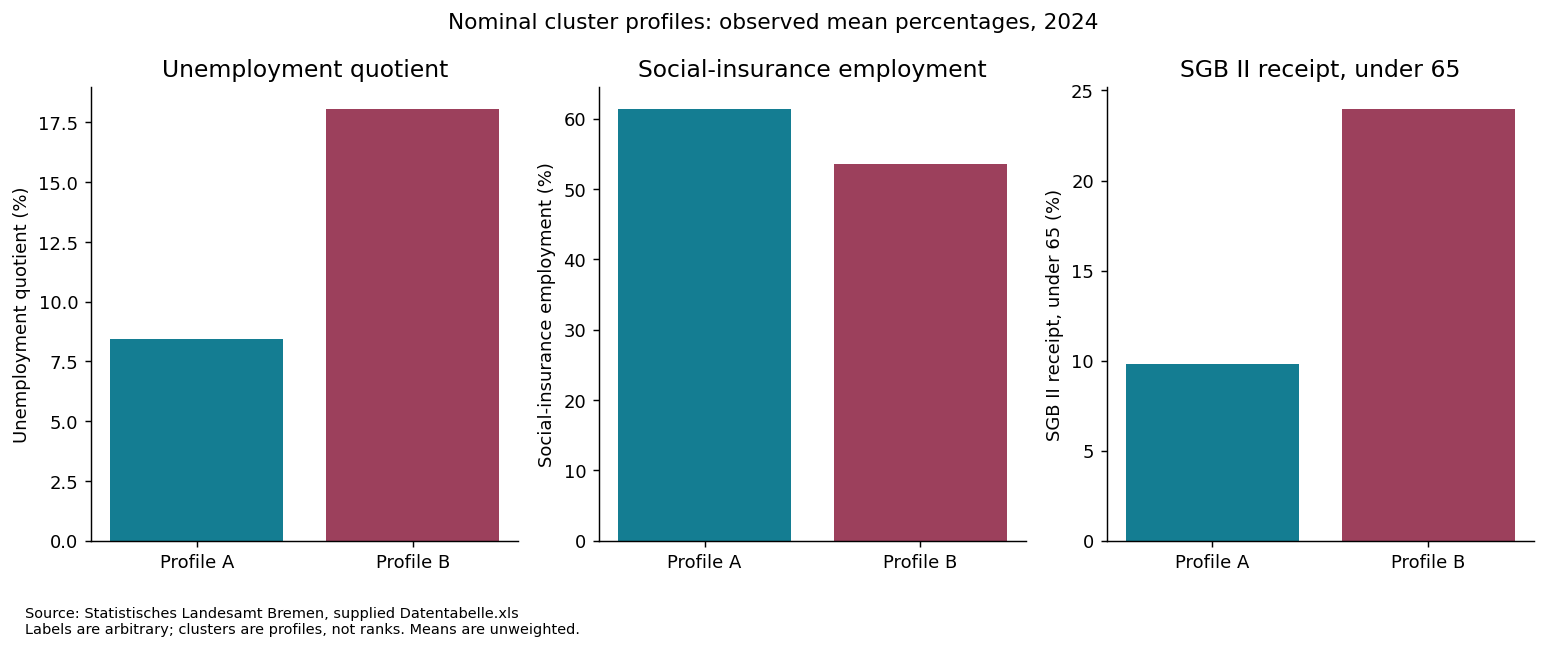

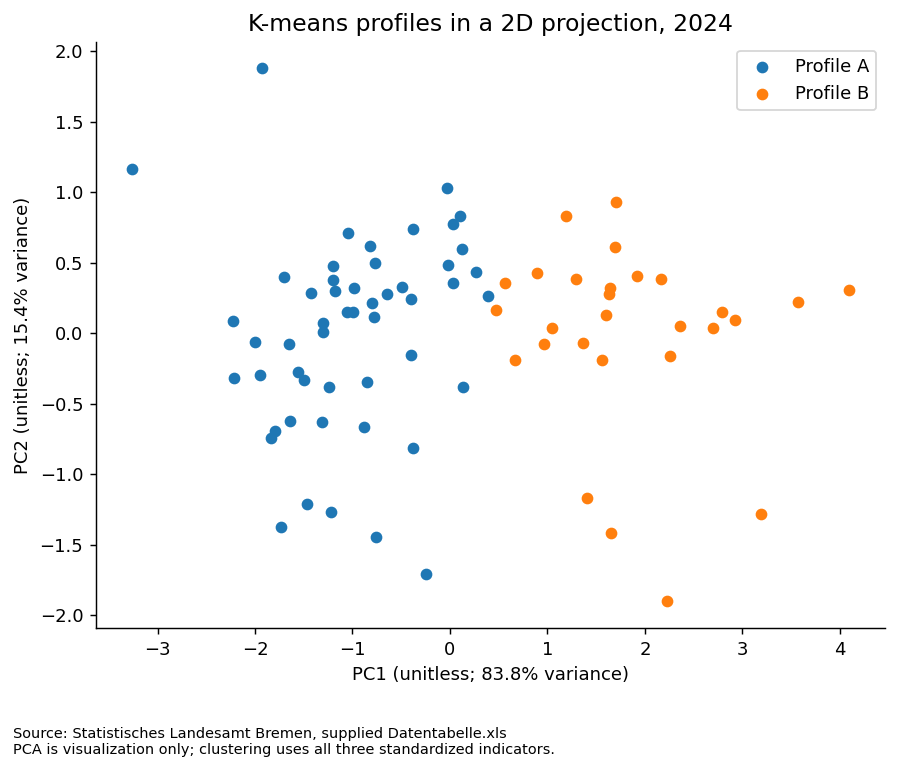

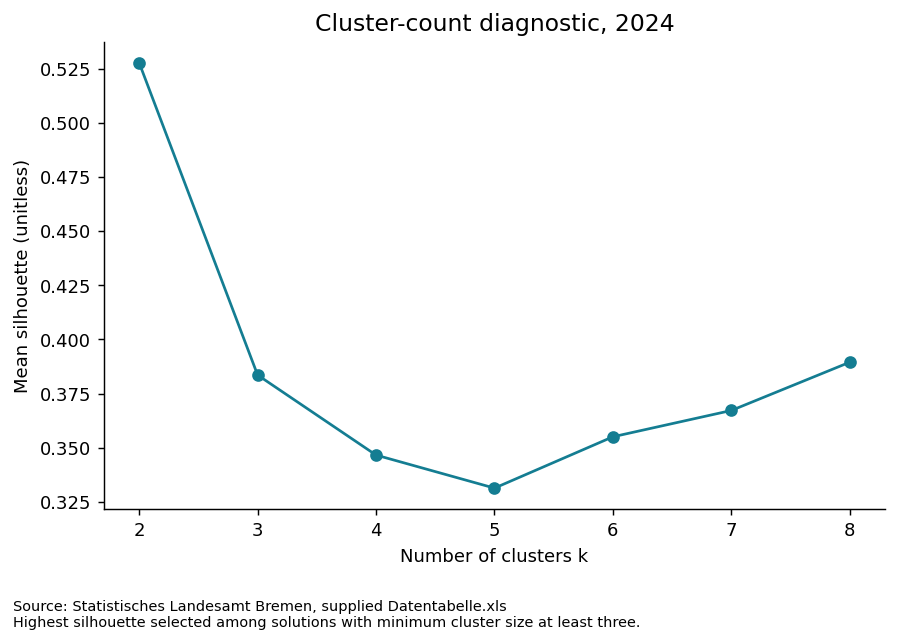

Profile labels are nominal. K-means uses three standardized variables; PCA is display only. Highest silhouette subject to minimum cluster size three selects k. Stability does not prove profile validity.

In [4]:
show_figure('cluster_profiles.png')
show_figure('cluster_projection.png')
show_figure('kmeans_diagnostics.png')
display(Markdown('Profile labels are nominal. K-means uses three standardized variables; PCA is display only. Highest silhouette subject to minimum cluster size three selects k. Stability does not prove profile validity.'))

## Assumptions and limits

Complete-case scoring; no imputation. Different indicator denominators, correlated labour-market measures, unavailable 2024 income, unknown exact reference dates and incomplete historical boundary/definition metadata limit interpretation. Rankings apply only to the covered sample. Clusters are nominal. See analysis/dataset_validation.md and docs/methods.md. Tables are exported by reusable scripts; important figures appear in results/figures/.